# Semi-supervised learning: few labels

<div class="roadmap"><div class="rm-sofar"><span>So far</span>A rule needs rows with known answers, and such answers are slow and costly to collect.</div><div class="rm-question"><b>What can be learned when answers are scarce?</b><span>Semi-supervised learning: a model trained on 30 labelled rows labels the other 1,429 itself (self-training).</span></div><div class="rm-steps"><div class="rm-step"><b>Which 30?</b><span>at random, or ten per class</span></div><div class="rm-step"><b>Self-training</b><span>the model labels the rest, in a loop</span></div><div class="rm-step"><b>The result</b><span>it depends on the 30</span></div><div class="rm-step"><b>Going deeper</b><span>when the repair fails</span></div></div></div>

Imagine the land-use label had to be collected by a field visit, and the budget covers 30 hexagons. A supervised model can only learn from those 30. A semi-supervised model also uses the POI profiles of the other 1,429, which cost nothing.

As on the pages before, **accuracy** means the share of hexagons whose label a model gets right, counted on hexagons whose label the model was not given.

## The experiment

**Which 30?** There are two obvious ways to choose them.

- **30 at random**, as a survey with no prior knowledge would draw them.
- **10 per class**, which guarantees examples of the rare class but presupposes that we already know roughly where each class is, for example from an older map.

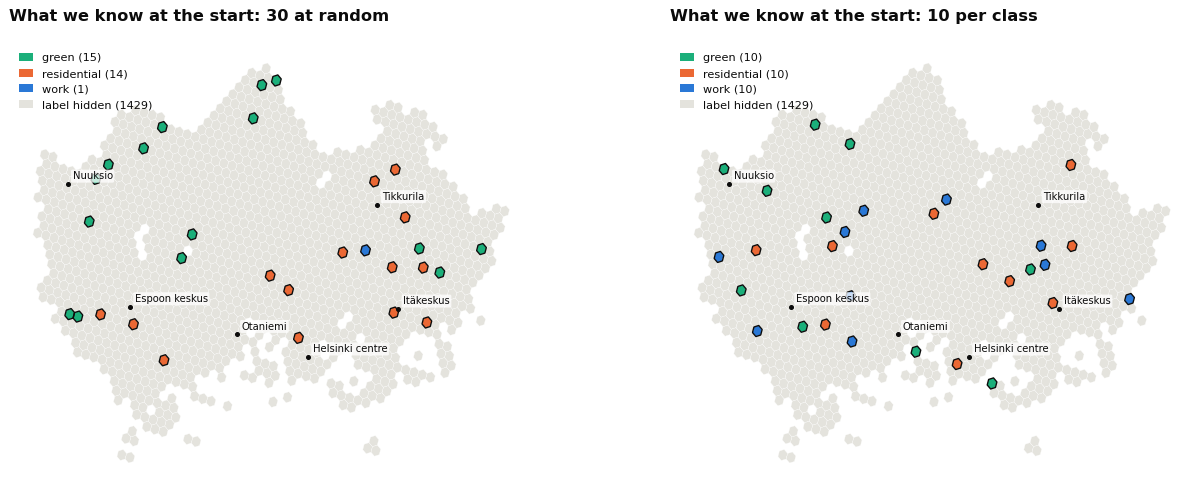

True shares of the classes: {'green': 51, 'residential': 39, 'work': 10}


In [29]:
N_LABELS = 30       # try 15, 60, 150
THRESHOLD = 0.80    # how sure the model must be before we believe its own prediction


def draw_labelled(seed, per_class):
    r = np.random.default_rng(seed)
    if per_class:
        return np.concatenate([r.choice(np.where(y == c)[0], N_LABELS // 3, replace=False) for c in CLASSES])
    return r.choice(len(y), N_LABELS, replace=False)


def hide_all_but(labelled):
    y_start = np.full(len(y), None, dtype=object)
    y_start[labelled] = y[labelled]
    return y_start


samples = {"30 at random": draw_labelled(SEED, per_class=False), "10 per class": draw_labelled(SEED, per_class=True)}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
for ax, (name, labelled) in zip(axes, samples.items()):
    h.map_classes(hexes, hide_all_but(labelled), ax=ax, outline=labelled, title=f"What we know at the start: {name}")
plt.tight_layout()
h.save(fig, "1_two_samples.png", SAVE)
plt.show()
print("True shares of the classes:", (pd.Series(y).value_counts(normalize=True).reindex(CLASSES) * 100).round(0).astype(int).to_dict())

**Self-training** is a loop:

1. train a model on the labelled hexagons,
2. let it predict the unlabelled ones,
3. keep the predictions it is very sure about and treat them as labels,
4. repeat.

The model is the boundary rule of the page on supervised learning (logistic regression). Each hexagon is described by its own POI profile and by its neighbours' profile (`X` and `X_around` side by side). Standardising the features needs no labels, so we standardise them once on all hexagons.

In [30]:
Z = StandardScaler().fit_transform(np.hstack([X, X_around]))


def new_model(C=1.0):
    return LogisticRegression(max_iter=2000, C=C)       # C is scikit-learn's default strength; smaller = more cautious


def self_train(F, y_start, threshold=0.80, C=1.0, max_rounds=40):
    """y_start holds a class name where the label is known and None where it is hidden.
    Returns the final model and a list with the label array after every round."""
    y_now = y_start.copy()
    history = [y_now.copy()]
    for _ in range(max_rounds):
        known = pd.notna(y_now)
        if known.all():
            break
        model = new_model(C).fit(F[known], y_now[known].astype(str))     # 1. train on what we have
        proba = model.predict_proba(F[~known])                           # 2. predict the rest
        sure = proba.max(axis=1) >= threshold                            # 3. keep the confident predictions
        if not sure.any():
            break
        y_now[np.where(~known)[0][sure]] = model.classes_[proba.argmax(axis=1)[sure]]
        history.append(y_now.copy())                                     # 4. repeat
    known = pd.notna(y_now)
    return new_model(C).fit(F[known], y_now[known].astype(str)), history

In [31]:
runs = {}
for name, labelled in samples.items():
    y_start = hide_all_but(labelled)
    hidden = pd.isna(y_start)
    supervised = new_model().fit(Z[labelled], y[labelled])
    model_self, history = self_train(Z, y_start, THRESHOLD)
    runs[name] = dict(labelled=labelled, y_start=y_start, hidden=hidden, history=history,
                      pred_supervised=supervised.predict(Z), pred_self=model_self.predict(Z))
    acc_sup = (runs[name]["pred_supervised"][hidden] == y[hidden]).mean()
    acc_self = (runs[name]["pred_self"][hidden] == y[hidden]).mean()
    runs[name].update(acc_supervised=acc_sup, acc_self=acc_self)
    print(f"{name}:  supervised {acc_sup:.1%}   self-training {acc_self:.1%}   ({len(history) - 1} rounds)")
print(f"Always guessing the largest class: {(y == 'green').mean():.1%}\n")

run = runs["30 at random"]
labelled, y_start, hidden, history = run["labelled"], run["y_start"], run["hidden"], run["history"]
print("Round by round, for the 30 hexagons drawn at random:")
for r, y_r in enumerate(history):
    adopted = pd.notna(y_r) & hidden
    note = f"of the adopted labels {(y_r[adopted] == y[adopted]).mean():.0%} are right" if adopted.any() else "the labels we were given"
    print(f"  round {r:2d}: {pd.notna(y_r).sum():5d} hexagons carry a label; {note}")

30 at random:  supervised 72.6%   self-training 72.7%   (8 rounds)


10 per class:  supervised 71.8%   self-training 76.3%   (11 rounds)
Always guessing the largest class: 51.2%

Round by round, for the 30 hexagons drawn at random:
  round  0:    30 hexagons carry a label; the labels we were given
  round  1:  1238 hexagons carry a label; of the adopted labels 76% are right
  round  2:  1378 hexagons carry a label; of the adopted labels 74% are right
  round  3:  1405 hexagons carry a label; of the adopted labels 74% are right
  round  4:  1414 hexagons carry a label; of the adopted labels 73% are right
  round  5:  1421 hexagons carry a label; of the adopted labels 73% are right
  round  6:  1424 hexagons carry a label; of the adopted labels 73% are right
  round  7:  1425 hexagons carry a label; of the adopted labels 73% are right
  round  8:  1426 hexagons carry a label; of the adopted labels 73% are right


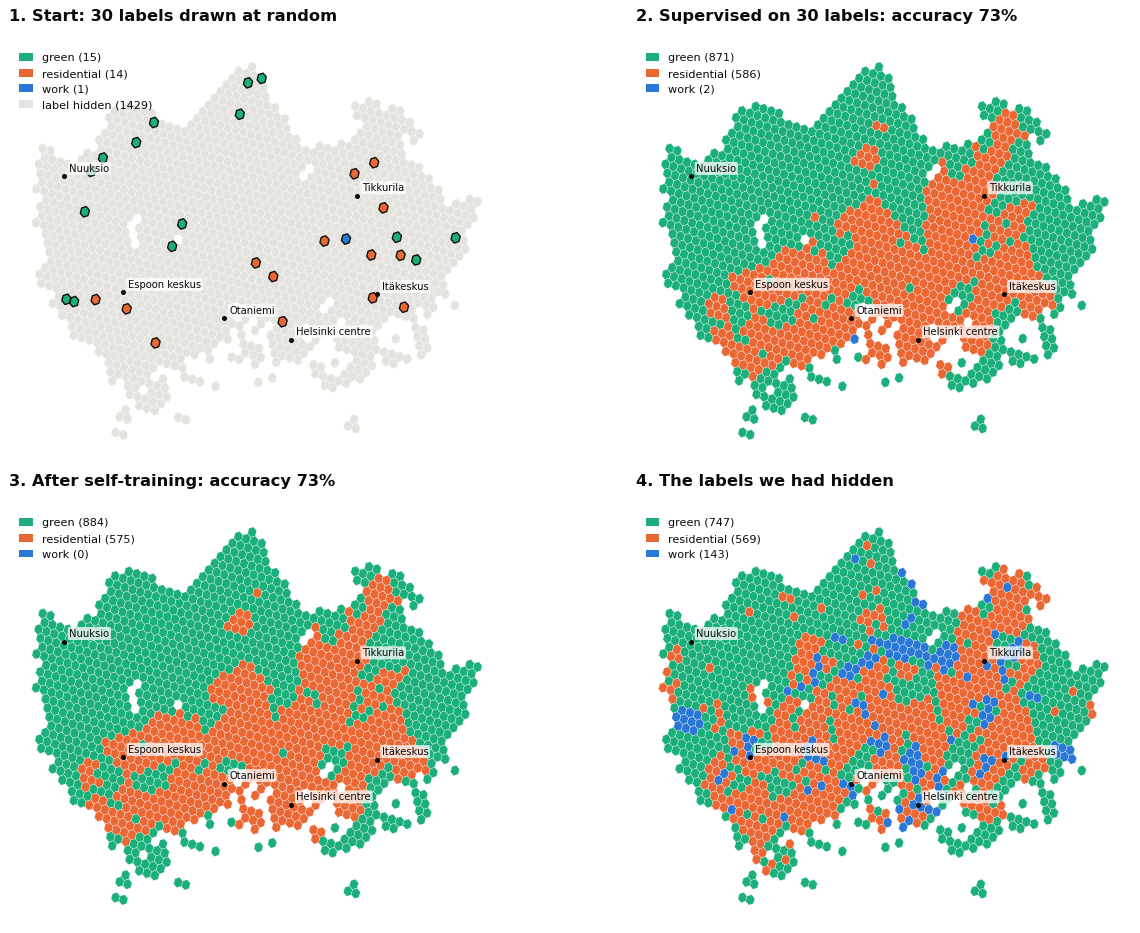

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10.5))
h.map_classes(hexes, y_start, ax=axes[0, 0], title=f"1. Start: {N_LABELS} labels drawn at random", outline=labelled)
h.map_classes(hexes, run["pred_supervised"], ax=axes[0, 1], title=f"2. Supervised on {N_LABELS} labels: accuracy {run['acc_supervised']:.0%}")
h.map_classes(hexes, run["pred_self"], ax=axes[1, 0], title=f"3. After self-training: accuracy {run['acc_self']:.0%}")
h.map_classes(hexes, y, ax=axes[1, 1], title="4. The labels we had hidden")
plt.tight_layout()
h.save(fig, "1_selftraining_four_maps.png", SAVE)
plt.show()

Round by round, more hexagons carry a label. Grey hexagons have none yet.

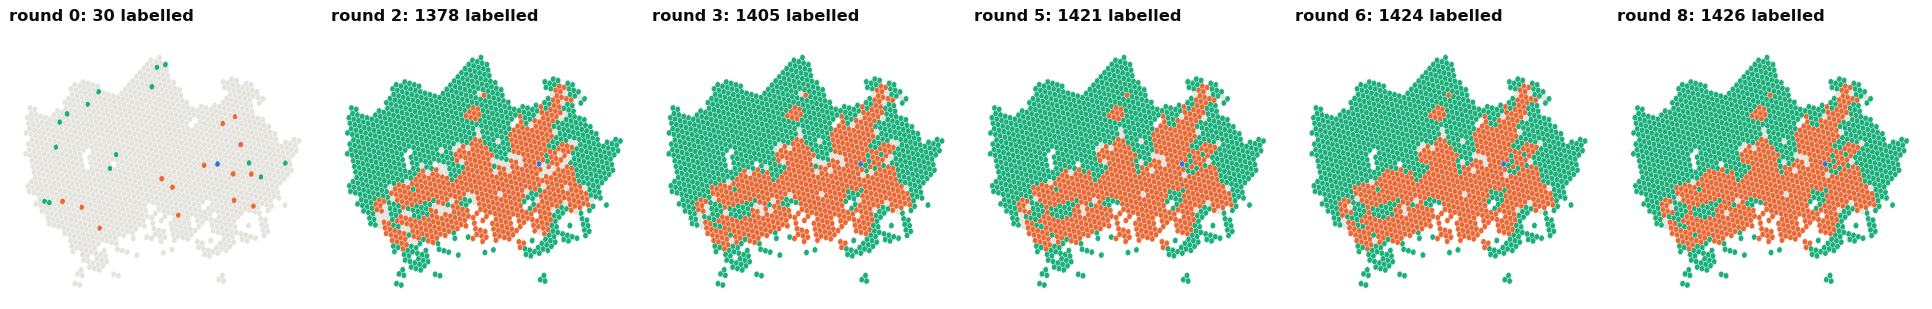

In [33]:
show = sorted(set(np.linspace(0, len(history) - 1, 6).round().astype(int)))
fig, axes = plt.subplots(1, len(show), figsize=(3.6 * len(show), 3.4))
for ax, r in zip(np.atleast_1d(axes), show):
    h.map_classes(hexes, history[r], ax=ax, places=False, legend=False,
                  title=f"round {r}: {pd.notna(history[r]).sum()} labelled")
plt.tight_layout()
h.save(fig, "1_selftraining_rounds.png", SAVE)
plt.show()

<div class="frames" data-name="selftraining" data-prefix="round" data-first="0"></div>

*Self-training, round by round. Grey hexagons have no label yet; outlined hexagons are the 30 we started with.*

> **What did we just see?** The model started from 30 labels, adopted its own most confident predictions, retrained, and went on to less certain hexagons. Three things are worth noticing.
>
> - After seeing only 30 labels, the model is already at least 80% sure about most of the hexagons, and it is wrong about roughly one in four of those. Being confident is not the same as being right, and the wrong labels become training data in the next round.
> - The newly labelled hexagons appear all over the map from the first round. Self-training moves through the *features*, from hexagons that look like a labelled one to hexagons that look less like it, and not outward across the map.
> - Compare the two samples in the printed lines above. The method is the same and the result is not. The next section asks why.

## Going deeper

**One draw is an anecdote.** We repeat the experiment with twelve different sets of 30 hexagons for each way of choosing them, and we record how often each model predicts the rare class, `work`.

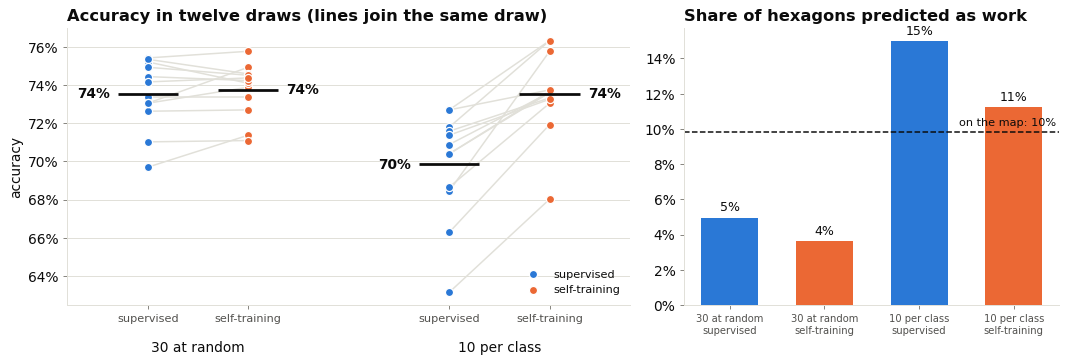

,supervised,self-training,"work, supervised","work, self-training"
sample,,,,
30 at random,73.5,73.8,5.0,3.6
10 per class,69.9,73.6,15.0,11.2


In [34]:
def one_draw(seed, per_class):
    lab = draw_labelled(seed, per_class)
    start = hide_all_but(lab)
    hid = pd.isna(start)
    sup = new_model().fit(Z[lab], y[lab]).predict(Z[hid])
    st = self_train(Z, start, THRESHOLD)[0].predict(Z[hid])
    return {"supervised": (sup == y[hid]).mean(), "self-training": (st == y[hid]).mean(),
            "work, supervised": (sup == "work").mean(), "work, self-training": (st == "work").mean()}


draws = pd.DataFrame([{"sample": name, "seed": s, **one_draw(s, per_class)}
                      for name, per_class in (("30 at random", False), ("10 per class", True)) for s in range(12)])
means = draws.groupby("sample", sort=False).mean(numeric_only=True).drop(columns="seed")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
for g, (name, part) in enumerate(draws.groupby("sample", sort=False)):
    x0, x1 = g * 3, g * 3 + 1
    for _, row in part.iterrows():
        ax.plot([x0, x1], [row["supervised"], row["self-training"]], color=h.GRID, linewidth=1.2, zorder=1)
    ax.scatter(np.full(len(part), x0), part["supervised"], s=42, color="#2a78d6", edgecolor="white", linewidth=1, zorder=3, label="supervised" if g == 0 else None)
    ax.scatter(np.full(len(part), x1), part["self-training"], s=42, color="#eb6834", edgecolor="white", linewidth=1, zorder=3, label="self-training" if g == 0 else None)
    for x, col, side in ((x0, "supervised", -1), (x1, "self-training", 1)):
        ax.hlines(part[col].mean(), x - 0.3, x + 0.3, color=h.INK, linewidth=2.2, zorder=4)
        ax.text(x + side * 0.38, part[col].mean(), f"{part[col].mean():.0%}", ha="right" if side < 0 else "left", va="center",
                fontsize=11, fontweight="bold", zorder=5)
    ax.text((x0 + x1) / 2, -0.13, name, ha="center", va="top", fontsize=11, transform=ax.get_xaxis_transform())
ax.set_xticks([0, 1, 3, 4], ["supervised", "self-training"] * 2, fontsize=9)
ax.set_xlim(-0.8, 4.8)
ax.set_ylabel("accuracy")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.yaxis.grid(True, color=h.GRID)
ax.set_title("Accuracy in twelve draws (lines join the same draw)")
ax.legend(loc="lower right", fontsize=9)

ax = axes[1]
labels = ["30 at random\nsupervised", "30 at random\nself-training", "10 per class\nsupervised", "10 per class\nself-training"]
values = [means.loc["30 at random", "work, supervised"], means.loc["30 at random", "work, self-training"],
          means.loc["10 per class", "work, supervised"], means.loc["10 per class", "work, self-training"]]
ax.bar(range(4), values, width=0.6, color=["#2a78d6", "#eb6834", "#2a78d6", "#eb6834"])
for i, v in enumerate(values):
    ax.text(i, v + 0.004, f"{v:.0%}", ha="center", fontsize=10)
true_work = (y == "work").mean()
ax.axhline(true_work, color=h.INK, linestyle="--", linewidth=1.2)
ax.text(3.45, true_work + 0.004, f"on the map: {true_work:.0%}", ha="right", fontsize=9)
ax.set_xticks(range(4), labels, fontsize=8)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Share of hexagons predicted as work")
plt.tight_layout()
h.save(fig, "1_two_designs.png", SAVE)
plt.show()
(means * 100).round(1)

> **What did we just see?** With 30 hexagons drawn at random, self-training changes little: some draws go up, some go down. With ten per class it gains in almost every draw. The right-hand chart shows the reason. Ten per class makes a third of the labelled hexagons `work`, although about a tenth of the map is. The supervised model learns those proportions and predicts `work` too often. The unlabelled hexagons pull the proportions back towards those of the map.
>
> So self-training did not discover new knowledge here. It repaired a labelled sample that misrepresented the map, and a sample that represents the map needed no repair. Neither sample is simply better: the random one matches the class proportions and may contain a single `work` hexagon, while ten per class guarantees examples of the rare class and distorts the proportions. Which one you want depends on what the map is for.

**How fragile is the repair?** The gain above belongs to one model. Logistic regression has a setting, `C`, for how strongly it trusts its training data; we used scikit-learn's default. A more cautious model (`C = 0.1`) is a sensible choice with 30 labels and 32 features. What happens then?

In [35]:
rows = []
for C, model_name in ((1.0, "default (C = 1)"), (0.1, "more cautious (C = 0.1)")):
    for sample, per_class in (("30 at random", False), ("10 per class", True)):
        sup, st, wrong = [], [], []
        for s in range(12):
            lab = draw_labelled(s, per_class)
            start = hide_all_but(lab)
            hid = pd.isna(start)
            sup.append((new_model(C).fit(Z[lab], y[lab]).predict(Z[hid]) == y[hid]).mean())
            model, hist = self_train(Z, start, THRESHOLD, C=C)
            st.append((model.predict(Z[hid]) == y[hid]).mean())
            adopted = pd.notna(hist[-1]) & hid
            wrong.append((hist[-1][adopted] != y[adopted]).mean())
        rows.append({"model": model_name, "sample": sample, "supervised": np.mean(sup), "self-training": np.mean(st),
                     "worst draw, self-training": np.min(st), "adopted labels that are wrong": np.mean(wrong)})
fragile = pd.DataFrame(rows).set_index(["model", "sample"])
(fragile * 100).round(1)

supervised  self-training  \
model                   sample                                    
default (C = 1)         30 at random        73.5           73.8   
                        10 per class        69.9           73.6   
more cautious (C = 0.1) 30 at random        73.3           73.0   
                        10 per class        74.2           44.8   

                                      worst draw, self-training  \
model                   sample                                    
default (C = 1)         30 at random                       71.1   
                        10 per class                       68.0   
more cautious (C = 0.1) 30 at random                       70.0   
                        10 per class                       36.5   

                                      adopted labels that are wrong  
model                   sample                                       
default (C = 1)         30 at random                           25.0  
                        10 per class                           24.8  
more cautious (C = 0.1) 30 at random                           24.6  
                        10 per class                           54.6

> **What did we just see?** With ten labels per class, the more cautious model is as accurate *without* any unlabelled hexagon as the default model is after self-training. So the repair was needed by one model, not by the sample as such. And when the cautious model is self-trained, it collapses: more than half of the labels it adopts are wrong, and each round trains on the mistakes of the round before.
>
> Self-training is fragile. On this dataset its outcome depended on how the 30 hexagons were chosen, on the threshold and on a setting of the model, and it ranged from a gain of a few points to a collapse. Unlabelled data are no free lunch: test the method on your own data before you trust it.

**Geography alone.** The opposite extreme: ignore the POIs entirely and let each labelled hexagon pass its label to its neighbours, who pass it on to theirs. This is *label propagation* on the hexagon grid, using only `W`.

Label propagation from 30 random labels, geography only: accuracy 61.9% in this draw, 55.6% on average over twelve draws (always guessing green: 51.2%)


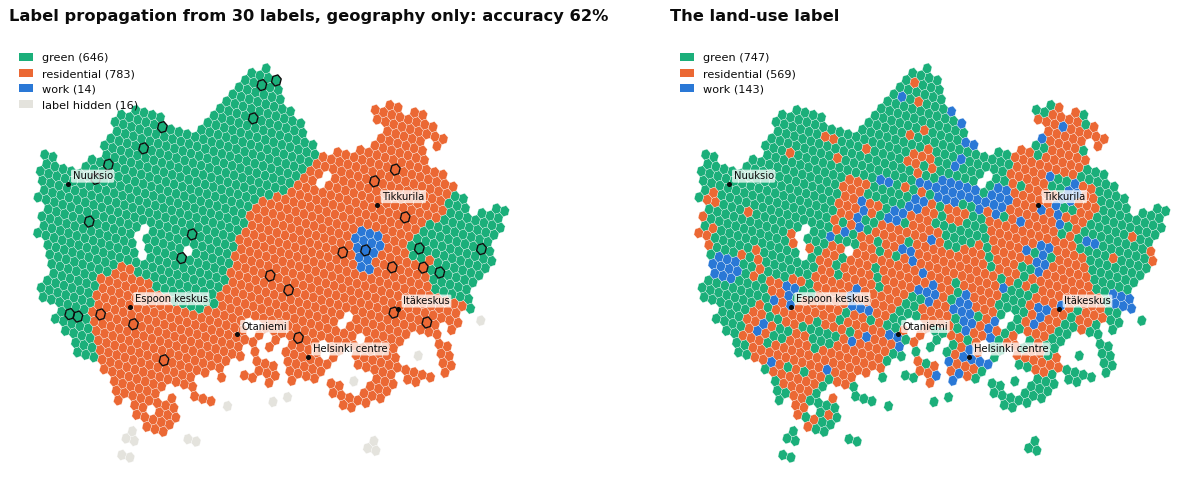

In [36]:
def propagate(y_start, W, rounds=300, keep=0.9):
    start = np.stack([(y_start == c).astype(float) for c in CLASSES], axis=1)   # one column per class
    score = start.copy()
    for _ in range(rounds):
        score = keep * (W @ score) + (1 - keep) * start      # take the neighbours' average, keep the known labels
    pred = np.array(CLASSES, dtype=object)[score.argmax(axis=1)]
    pred[score.sum(axis=1) == 0] = None                      # hexagons no label ever reached
    return pred


pred_geo = propagate(y_start, W)
acc_geo = (pred_geo[hidden] == y[hidden]).mean()
acc_geo_draws = [np.mean(propagate(hide_all_but(lab), W)[np.setdiff1d(np.arange(len(y)), lab)] == np.delete(y, lab))
                 for lab in (draw_labelled(s, False) for s in range(12))]
print(f"Label propagation from {N_LABELS} random labels, geography only: accuracy {acc_geo:.1%} in this draw, "
      f"{np.mean(acc_geo_draws):.1%} on average over twelve draws (always guessing green: {(y == 'green').mean():.1%})")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
h.map_classes(hexes, pred_geo, ax=axes[0], outline=labelled,
              title=f"Label propagation from {N_LABELS} labels, geography only: accuracy {acc_geo:.0%}")
h.map_classes(hexes, y, ax=axes[1], title="The land-use label")
plt.tight_layout()
h.save(fig, "1_label_propagation.png", SAVE)
plt.show()

> **What did we just see?** Each labelled hexagon grows a territory around itself, like a Voronoi diagram (week 6). With 30 labels on 1,459 hexagons the territories are far too coarse: on average the result is only a few points better than always guessing `green`, and well below the supervised model that uses the POIs. Spatial dependence is real, and it is still not enough by itself here: adjacent hexagons are alike, but 30 seeds cannot know where the forest ends. In the notebook, set `N_LABELS = 300` and run the cells of this page again.

## Your turn

- Change `N_LABELS` to 15, 60 and 150 and run the cells of this page again. Does the difference between the two samples remain?
- Set `THRESHOLD = 0.5`, then `0.95`. What happens to the number of rounds and to the share of adopted labels that are right?
- Repair the ten-per-class sample without self-training: give each labelled hexagon a weight equal to its class's share on the map (`new_model().fit(Z[lab], y[lab], sample_weight=...)`). How close does the supervised model come to the self-trained one? In practice, where would those shares come from?
- Describe each hexagon by its own profile alone: replace `Z` by `StandardScaler().fit_transform(X)`. What changes?
- Label propagation and self-training use different information. Can you combine them, for example by adding the propagated scores as extra features?

**Ask an AI assistant**

> I have a NumPy feature matrix `Z` (n × 32), an array `y_start` with class names for 30 rows and `None` elsewhere, and a function `self_train(Z, y_start, threshold)` that returns `(model, history)`. Write a short loop that runs it for thresholds 0.5 to 0.95 and plots the final accuracy on the hidden rows, where the full labels are in `y`. Use matplotlib only.

Then check its answer: does it measure accuracy only on the rows that were hidden at the start?